### Exam PSY-3035, Marie Bøe Aaberg
# Personal Sleep Statistics

For this exam I have chosen to use my own recorded sleep statistics containing sleep duration, sleep health, and sleep habits. This was chosen as it allows me to gain a better understanding of my own efforts to improve my overall health and monitor which applied changes make an impact on my sleep. The presented figures thus monitor various aspects of this journey in hopes of observing improvements aswell as negative changes that allow me to reflect around why and through that alter my sleep habits if necessary. Despite active efforts to improve my sleep, the data may not show consistent improvement or clear patterns over time. This may be influenced by several confounding factors, particularly my chronic pain, which is not being tracked and therefore cannot be accounted for in the analyses.

Explanations of the code will mainly be provided on the same line as said code, but will be further elaborated on afterwards when relevant. AI has throughout this exam been used to code time conversion. Although some other sources were available for this code (pandas.Timedelta, 2026; Time deltas, 2026), I found them difficult to understand and make use of. I have therefore decided to leave in the AI code while providing the original source material I asked it to base it on. 

Additionally the exam will state that hypotheses are confirmed or rejected. Although such conclusions based on limited figures alone would be wrong in more comprehensive studies and words like supported/not supported should be utilized instead, I have still chosen to use this terminology for convenience as it fulfills exam requirements (2.3 and 4.2 on rubric).

## Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from scipy import stats

In [3]:
filename = "sleep_avg.xlsx"
data = pd.read_excel(filename)

print(data)

  week        S1        S2        S3        M1        M2       ST  \
0  W38  23:00:00  23:19:00  00:11:00  09:36:00  10:02:00  10h 43m   
1  W39  22:18:00  22:38:00  23:27:00  09:05:00  09:22:00  10t 44m   
2  W40  22:56:00  23:19:00  23:42:00  08:37:00  09:30:00  10t 11m   
3  W41  00:04:00  00:58:00  01:27:00  08:55:00  10:13:00   9t 16m   
4  W42  00:19:00  00:32:00  00:47:00  09:39:00  10:23:00   9t 51m   
5  W43  22:57:00  23:27:00  23:50:00  09:00:00  09:45:00  10t 19m   

   ST_duration_minutes      VT  VT_duration_minutes   sleep  \
0                  643  1h 19m                   79  9t 24m   
1                  644  1t 12m                   72  9t 31m   
2                  611  1t 16m                   76  8t 55m   
3                  556  1t 48m                  108  7t 28m   
4                  591  0t 58m                   58  8t 52m   
5                  619   1t 9m                   69  9t 10m   

   sleep_duration_minutes  sleep_efficiency  sleep_quality  day_feeling  


This dataset is made using weekly averages. It includes information on:

- The week
- Time of getting into bed but not deciding to go to sleep (S1, referred to as "prior to bedtime")
- Time of deciding when to go to sleep (S2, referred to as "bedtime")
- Sleep onset time (S3)
- Wake-up time (M1)
- Time of when I left the bed (M2, referred to as "get-up time")
- Total time in bed excluding S1(ST = M2 - S2)
- Time in bed spent awake (VT = (S3-S2) + Sum of times waking up during the night + (M2-M1))
- Time in bed spent asleep (sleep = ST - VT)
- The effiency of said sleep in percentages (coded as SE, SE = sleep / ST)
- Sleep quality and day feeling on a 1-5 scale (very bad-very good, coded as SQ and DF)

ST, VT, and sleep are recorded in both an hour and minute format and a minute format for personal convenience, but only the minute format (x_duration_minutes) is utilized in this exam.

## 1. Sleep Duration

### 1.1 Pie Chart:  Time Spent in Bed

I do not have any hypotheses regarding sleep duration. My goal with this figure is to track how much time I spend in bed in total, and how that time is spent. It will not track any changes, but allows me to optimize if the overall results skews too much in an unfavorable direction.

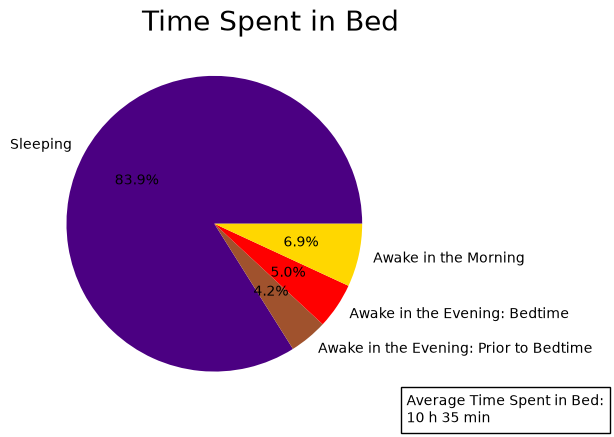

In [ ]:
#Figure 1.1
#Converts clock times to minutes after midnight. AI has been used for this (based on: Hunter et al., 2026b; Hunter et al., 2026d; pandas.Timedelta, 2026; Time deltas, 2026).
def to_minutes(column):
    return pd.to_timedelta(
        data[column].astype(str)
    ).dt.total_seconds() / 60

#To get the program to recognize the data and converts the 24-hour format to minutes in order to calculate awake times
S1=to_minutes("S1")
S2=to_minutes("S2")
S3=to_minutes("S3")
M1=to_minutes("M1")
M2=to_minutes("M2")

data["awake_pre_bedtime"]=(S2-S1) % 1440
data["awake_bedtime"]=(S3-S2) % 1440                    #Calculates awake time in the evening prior to bedtime from the 24-hour clock. Sleep onset time(S3) - Bedtime(S2). %1440 is an additional step to account for midnight changing the values from 23:xx to 00:xx
data["awake_morning"]=(M2-M1)                           #Calculates awake time in the morning from the 24-hour clock. Get-up time(M2) - Wake-up time(M1).

# Calculates the average durations across weeks so the piechart get a single value to deal with
sleep=data["sleep_duration_minutes"].mean()
pre_bedtime=data["awake_pre_bedtime"].mean()
bedtime=data["awake_bedtime"].mean()
morning=data["awake_morning"].mean()

#To calculate the average total time spent in bed for plt.text() using hours and minutes
time_in_bed = sleep + pre_bedtime + bedtime + morning
hours = int(time_in_bed // 60)
minutes = int(time_in_bed % 60)

values=[sleep, pre_bedtime, bedtime, morning]               #Sets the values. Could also be done in plt.pie() but with all the necessary details for the chart this is a clearer and easier to understand structure
labels=[                                                    #Names the labels in the same order as values(sleep, then evening, then morning)
    "Sleeping",
    "Awake in the Evening: Prior to Bedtime",
    "Awake in the Evening: Bedtime",
    "Awake in the Morning"
]

plt.pie(                                                    #(Simply Coding, 2020)
    values,                                                 #Values because it is defined above
    labels=labels,                                          #Labels that were decided upon above (Hunter et al., 2026c)
    autopct="%2.1f%%",                                      #Percentages
    colors=["indigo", "sienna", "red", "gold"]              #Colors. Follows the same order as values(sleep, then evening, then morning) (Hunter et al., 2026a; Phillips, 2022).
    )   

plt.title("Time Spent in Bed", fontsize=20, loc="right")    #Title
plt.text(                                                   #Adds average time spent in bed text at the bottom (Kimberly Fessel, 2021).
    1.02, -0.05,                                            #So that it has a grid to place the text by the bottom (Hunter et al., 2026e; Kimberly Fessel, 2021)
    f"Average Time Spent in Bed:\n{hours} h {minutes} min", #f before quotation marks lets you insert python variables directly into text. Hours/minutes transforms the minutes into text. /n is for a new line.
    transform=plt.gca().transAxes,                          #So that it has a grid to place the text
    fontsize=10,                                            #Fontsize
    verticalalignment="bottom",                             #Places text at bottom
    bbox=dict(                                              #Adds a box outlining the text
    facecolor="none",                                       #No background color
        edgecolor="black",                                  #Border color
    )
)

plt.show()                                                  #Displays the piechart

#### Why a Pie Chart?
A pie chart (Simply Coding, 2020) was chosen as it shows how much of my time in bed is spent either awake in the evening (bedtime & prior to it), sleeping, or awake in the morning. Time awake in the evening has been split into two sectors as time spent in bed without the intention to fall asleep (e.g. reading a book) differs greatly from time spent in bed with the intention of going to sleep. Later figures will analyse how these variables impact sleep health. In the dataset there is already a variable for time spent in bed(ST), but as it is mainly used for mathematical reasons regarding sleep and sleep efficiency it does not account for time spent in bed not intending to sleep. The prior to bedtime sector is not necessary, but as the figure is utilized to get an overarching picture of my habits I deemed it valuable to include. Average time spent in bed is thus calculated including the prior to bedtime sector and not by utilizing ST.

#### Color Choices
Although brown(sienna) and red (Hunter et al., 2026a) are very similar and possibly thus a bad choice, I have still chosen them to represent time awake in the evening. Here I value the similarity in color representing the same part of the day over visibility for those with color vision impairments. The ability to differenciate certain colors is deemed as less important in this instance as there are percentages representing the values (Simply Coding, 2020). Red tones have been chosen as longer time spent in bed prior to sleep is generally regarded as a negative for good sleep hygiene. Time spent in bed trying to sleep is thus red as to indicate it being worse for sleep health than time otherwise spent in bed during the evening (assuming no technology is being used) which has been labelled using brown for that reason.

Indigo has been chosen for sleep as it is a dark calming color frequently associated with sleep. Meanwhile yellow (Hunter et al., 2026a) has been chosen for the opposite reason as it is vibrant, inviting, and stimulating, something usually welcomed in the morning. All colors except the red/brown evening combination are to my knowledge accessible for the color impaired (Phillips, 2022).

#### Additional Visual Choices
Percentages have been chosen as they made a lot of sense to use for a general idea of how much each sector occupies overall time spent in bed (Simply Coding, 2020). Attempts were made to also include the average amount of time for each sector, but this became too cluttered to be useable. However, additional text has been added to include the overall average time spent in bed, giving a general idea of how much time each percentage represents. This additional text was logical to have on the bottom right, and has been given its own box without any filler color to avoid confusion and to make the overall visual more appealing (Hunter et al., 20263; Kimberly Fessel, 2021).

## 2. Sleep Habits

### Line Graphs:    Evening and Morning Habits

#### 2.1 Evening Habits
The line graph for the evening habits measures when I have gotten into bed without the intention of going to sleep(Prior to Bedtime), when I have decided to go to sleep(Bedtime), and Sleep Onset Time. In accordance with this I expect to see a positive correlation between average weekly time in bed prior to bedtime, bedtime and sleep onset time (H1) as you have to be in bed to decide to go to sleep and you need to have decided to go to sleep to fall asleep. I further expect to see that the time between average weekly bedtime and average weekly sleep onset time eventually stabilizes as more datapoints are added resulting in a difference consisting of 10 minutes or less between bedtime and sleep onset time(H2). In line with this I expect my bedtime to stabilize to be roughly within the average bedtime(H3) as my sleep schedule improves and more data entries are added (e.g. Bedtime is consistently between 23:00 and 00:00 while the average is 23:30).

#### 2.2 Morning Habits
The line graph for the morning habits measures when I wake up(Wake-Up Time) and when I get out of bed(Get-Up Time). As with the evening habits I expect my average weekly wake-up time to positively correlate with my average weekly get-up time(H4) since you cannot get out of bed before you have woken up. Similarly to evening habits I expect my average weekly wake-up time to stabilize over time(H5) as more data is entered and my sleep hygiene improves. However, morning habits diverge from evening habits in that I expect no consistent pattern in this figure for average weekly get-up time beyond a positive correlation with wake-up time(H6). This lack of pattern is expected as my chronic condition demands me to start my day differently depending on pain levels. This may become apparent in later figures as this time spent in bed in the morning may be impacted by sleep quality, or impact daytime feeling.

#### I therefore hypothesize that:

H1:     The time between average weekly bedtime and average weekly sleep onset time will eventually stabilize to be 10 minutes apart or less.

H2:     Average weekly bedtime stabilizes as more data is introduced.

H3:     Average weekly wake-up time stabilizes as more data is introduced.

H4:     Average weekly get-up time has no consistent pattern beyond a positive correlation with wake-up time.

C:\Users\marie\AppData\Local\Temp\ipykernel_12440\4027464439.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  S1 = pd.to_datetime(data["S1"].astype(str)).dt.hour + \
C:\Users\marie\AppData\Local\Temp\ipykernel_12440\4027464439.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(data["S1"].astype(str)).dt.minute / 60
C:\Users\marie\AppData\Local\Temp\ipykernel_12440\4027464439.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  S2 = pd.to_datetime(data["S2"].astype(str)).dt.hour + \
C:\Users\marie\AppData\Local\Temp\ipykernel_12440\4027464439.py:9: UserWarn

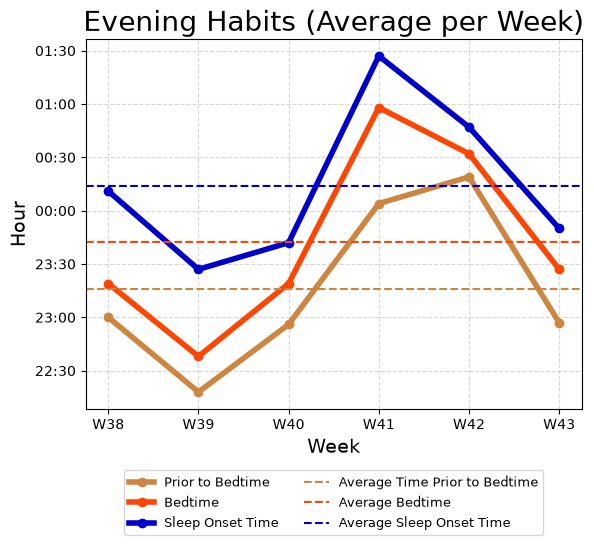

In [ ]:
#Figure 2.1
week = data["week"]           #To get the program to recognize the data

S1 = pd.to_datetime(data["S1"].astype(str)).dt.hour + \
     pd.to_datetime(data["S1"].astype(str)).dt.minute / 60
S1 = S1.where(S1 >= 12, S1 + 24)

S2 = pd.to_datetime(data["S2"].astype(str)).dt.hour + \
     pd.to_datetime(data["S2"].astype(str)).dt.minute / 60
S2 = S2.where(S2 >= 12, S2 + 24)

S3 = pd.to_datetime(data["S3"].astype(str)).dt.hour + \
     pd.to_datetime(data["S3"].astype(str)).dt.minute / 60
S3 = S3.where(S3 >= 12, S3 + 24)


def format_time(x, pos):
    hour = int(x) % 24
    minutes = int(round((x - int(x)) * 60))
    return f"{hour:02d}:{minutes:02d}"

plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_time))
plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(0.5))

#The code above except for "week=data["week"]" has derived from AI. Finding information on how to do this through traditional methods proved too difficult. The hour + minute columns in the datasets are not registered in the necessary form for python to properly read it.
#This is in order to make the code have a 24 hour clock format and so that the graph goes from 23:59 to 00:00 without jumping from the top of the graph to the bottom and thus include all 24 hours. (based on: Hunter et al., 2026b; Hunter et al., 2026d; pandas.Timedelta, 2026; Time deltas, 2026).


avg_S1 = sum(S1) / len(S1)         #To get an average for Pre-Bedtime to make the graph more managable once the dataset grows.
avg_S2 = sum(S2) / len(S2)         #Average for Bedtime
avg_S3 = sum(S3) / len(S3)         #Average for Sleep Onset Time


plt.plot(                          #To get the plotted line for Pre-Bedtime (Visually Explained, 2025)
 week,                             #x-axis
 S1,                               #y-axis
 marker="o",                       #To make each datapoint more visible
 label="Prior to Bedtime",         #For plt.legend() to have the name of the line for Pre-Bedtime in the plot (Hunter et al., 2026c)
 color="peru",                     #Color (Hunter et al., 2026a; Phillips, 2022).
 linewidth=4                       #Width of the line
)

plt.plot(                          #Same as above but for Bedtime (Visually Explained, 2025)
 week,                        
 S2,                          
 marker="o",                  
 label="Bedtime",                  #(Hunter et al., 2026c)
 color="orangered",                #(Hunter et al., 2026a; Phillips, 2022)
 linewidth=4                  
)

plt.plot(                          #Same as above but for Sleep Onset Time (Visually Explained, 2025)
     week,
     S3,
     marker="o",
     label="Sleep Onset Time",     #(Hunter et al., 2026c)
     color="mediumblue",           #(Hunter et al., 2026a; Phillips, 2022)
     linewidth=4
)


plt.title("Evening Habits (Average per Week)", fontsize=20)                                    #Title label with an appropriate fontsize
plt.xlabel("Week", fontsize=14)                                                                #Label on x-axis
plt.ylabel("Hour", fontsize=14)                                                                #Label on y-axis
plt.axhline(avg_S1, linestyle="--", color="peru", label="Average Time Prior to Bedtime")       #The average for Pre-Bedtime with label for plt.legend() and appropriate styling (Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022).
plt.axhline(avg_S2, linestyle="--", color="orangered", label="Average Bedtime")                #The average for Bedtime with label for plt.legend() and appropriate styling (Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022).
plt.axhline(avg_S3, linestyle="--", color="mediumblue", label="Average Sleep Onset Time")      #The average for Sleep Onset Time with label for plt.legend() and appropriate styling (Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022).
plt.grid(True, linestyle="--", alpha=0.5)                                                      #To get an appropriately stylized grid along x- and y-axis so it is easier to see the where the values are. Alpha makes it more transparent and thus less visible (Grids in Matplotlib, 2026)

plt.legend(                                                                                    #To display names for datalines (Hunter et al., 2026c)
    loc="upper center",                                                                        #To decide on location
    bbox_to_anchor=(0.5, -0.15),                                                               #Anchors the box in place relative to graph so it doesn't interfere with the lines
    ncol=2,                                                                                    #Makes the legend two columns to save space
    fontsize=9                                                                                 #Fontsize
)

plt.show()                                                                                     #Displays graph

C:\Users\marie\AppData\Local\Temp\ipykernel_12440\2895406352.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  M1 = pd.to_datetime(data["M1"].astype(str)).dt.hour + \
C:\Users\marie\AppData\Local\Temp\ipykernel_12440\2895406352.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(data["M1"].astype(str)).dt.minute / 60
C:\Users\marie\AppData\Local\Temp\ipykernel_12440\2895406352.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  M2 = pd.to_datetime(data["M2"].astype(str)).dt.hour + \
C:\Users\marie\AppData\Local\Temp\ipykernel_12440\2895406352.py:10: UserWar

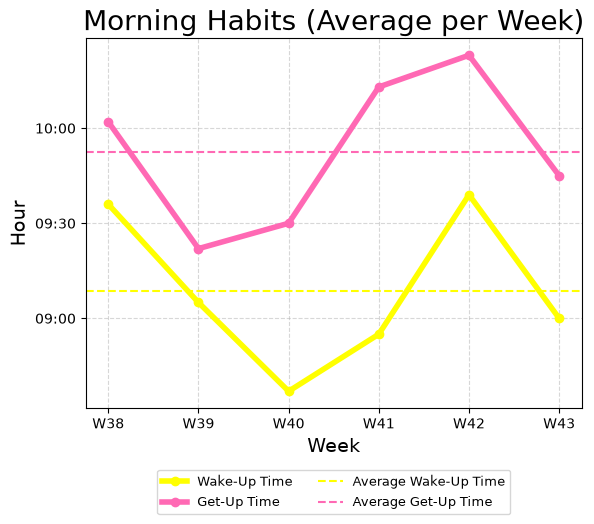

In [ ]:
#Figure 2.2
#Same exact setup as for the sleep habits except this time it is for morning habits(Wake-Up Time & Get-Up Time)
week = data["week"]

M1 = pd.to_datetime(data["M1"].astype(str)).dt.hour + \
     pd.to_datetime(data["M1"].astype(str)).dt.minute / 60
M1 = M1.where(M1 >= 12, M1 + 24)

M2 = pd.to_datetime(data["M2"].astype(str)).dt.hour + \
     pd.to_datetime(data["M2"].astype(str)).dt.minute / 60
M2 = M2.where(M2 >= 12, M2 + 24)


def format_time(x, pos):
    hour = int(x) % 24
    minutes = int(round((x - int(x)) * 60))
    return f"{hour:02d}:{minutes:02d}"

plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_time))
plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(0.5))
#AI has also been used for the code above (based on: Hunter et al., 2026b; Hunter et al., 2026d; pandas.Timedelta, 2026; Time deltas, 2026).


avg_M1 = sum(M1) / len(M1)
avg_M2 = sum(M2) / len(M2)


plt.plot(                                                                                 #(Visually Explained, 2025)
 week,
 M1,
 marker="o",
 label="Wake-Up Time",                                                                     #(Hunter et al., 2026c)
 color="yellow",                                                                           #(Hunter et al., 2026a; Phillips, 2022)
 linewidth=4
)

plt.plot(                                                                                  #(Visually Explained, 2025)
     week,
     M2,
     marker="o",
     label="Get-Up Time",                                                                  #(Hunter et al., 2026c)
     color="hotpink",                                                                      #(Hunter et al., 2026a; Phillips, 2022)
     linewidth=4
)


plt.title("Morning Habits (Average per Week)", fontsize=20)
plt.xlabel("Week", fontsize=14)
plt.ylabel("Hour", fontsize=14)
plt.axhline(avg_M1, linestyle="--", color="yellow", label="Average Wake-Up Time")          #(Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022)
plt.axhline(avg_M2, linestyle="--", color="hotpink", label="Average Get-Up Time")          #(Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022)
plt.grid(True, linestyle="--", alpha=0.5)                                                  #(Grids in Matplotlib, 2026)

plt.legend(                                                                                #(Hunter et al., 2026c)
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2, 
    fontsize=9
)

plt.show()

#### Results
 The duration between bedtime and sleep onset time(H1) in figure 2.1 seems to trend towards a smaller gap, but more data is needed to have a clear idea of consistency. Preliminary findings are positive though and suggests that currently applied methods are beneficial. H1 can therefore not be confirmed nor rejected as of now, but trends towards the hypothesis being confirmed at a later time. No similar hypothesis has been made regarding time spent in bed prior to bedtime as this time is meant to be open for intentionally including longer durations, and does not record insominac tendencies. Similarly to H1 bedtime(H2, figure 2.1) and wake-up time(H3, figure 2.2) stabilizing require more data to suggest a pattern and the hypotheses cannot be confirmed nor rejected at this point in time. The average weekly get-up time varies greatly from wake-up time in figure 2.2 in terms of how long it is between the two time points, which is expected due to non-sleep related health reasons, although due to the lack of data entries H4 cannot be confirmed nor rejected. It is expected that this lack of consistency continues as more data is collected, and when analyzed in later figures. The figures additionally show positive correlations between the time prior to bedtime, bedtime, and sleep onset time, as well as wake-up time and get-up time. This has however not been hypothesized on as common sense dictates that you cannot decide to sleep before going to bed, go to sleep before deciding to sleep, nor get out of bed before waking up.

#### Why Line Graphs?
Line graphs for evening and morning habits are being used in order to have a better understanding of how these habits evolve throughout the weeks (Visually Explained, 2025). This allows for systematically introducing new habits and noting whether they have a positive or negative impact, if they have any at all. By taking particular interest in bedtime and sleep onset time the evening habits graph (figure 2.2) allows me to track my sleep tendencies and record when (or if) insomniac traits re-emerge. These traits are apparent in the graph prior to week 40 when the introduction of an effective new sleep hygiene habit was introduced. Evening and morning habits have been made into two seperate figures as plotting them together offers no benefits while incorporating all waking hours into the figure and thus creating visual clutter and confusion. Averages have been added with the intention of better understanding my habits once there are sufficient data entries. The ideal is for the average bedtime and wake-up time to closely align with the weekly averages as per H3 and H5.

#### Color Choices
Colors have been chosen according to the colors used in the "Time Spent in Bed" pie chart in order to have visual consistency, while being slightly different due to it not being the exact same concept (i.e. sleep vs. sleep onset time). Evening habit colors are therefore in similar colors as time spent awake in bed in the evening and while sleeping. The "Prior to Bedtime" line gets a lighter brown(peru) to align with the brown(sienna) given to the "Awake in the Evening: Prior to Bedtime" sector in the above pie chart. Similarly "Bedtime" is given a reddish orange color(orangered) to align with the red(red) given to the "Awake in the Evening: Bedtime" sector. As well as "Sleep Onset Time" getting a blue color(mediumblue) to represent the time sleep occurs and thus aligning it with the "Sleep" sector consisting of a deep blue-ish color(indigo). Although this figure runs into the same issue as the pie chart where brown and red may impair peoples ability to differenciate the two, the nature of their content make for a natural assumption that "Prior to Bedtime" comes prior to "Bedtime" (Hunter et al., 2026a; Phillips, 2022).

Like with the evening habits the morning habits get colors aligning with the "Awake in the Morning" sector of the "Time Spent in Bed" pie chart. "Wake-Up Time" is given a yellow color(yellow) to align with the pie chart yellow color(gold). "Get-Up Time" is however not included in the pie chart and is thus given a contrasting color(hotpink) to accomodate for color vision impairments (Hunter et al., 2026a; Phillips, 2022).

#### Additional Visual Choices
Another visual choice that is introduced in these figures is a grid (Grids in Matplotlib, 2026). This is added for practical reasons which will grow in importance as the dataset expands. The grid is also made to be 50% transparent as to not take up too much visual space and distract from the presented information. Along with the grid the plt.legend() has been added to give adequate information on what the various lines are for (Hunter et al., 2026c). This has been modified to be a box below the figure consisting of both the line and the corresponding average per coded line to make it visually pleasant without taking up too much space or interupting anything within the figure such as overlapping with the graph lines. Additionally each datapoint has been accentuated with a circular dot to make the graph more accessible to read.



## 3. Sleep Health

### 3.1 Scatter Plot: Weekly Average Sleep Quality and Daytime Feeling in Relation to Weekly Average Sleep Efficiency

In this figure I am interested in exploring whether there is any correlation between sleep efficiency(SE), sleep quality(SQ), and daytime feeling(DF). I expect to see positive correlations such as:

H5:     Sleep Quality and Daytime Feeling show similar average weekly ratings.

H6:     Sleep Quality(H6A) and Daytime Feeling(H6B) positively correlate with Sleep Efficiency.

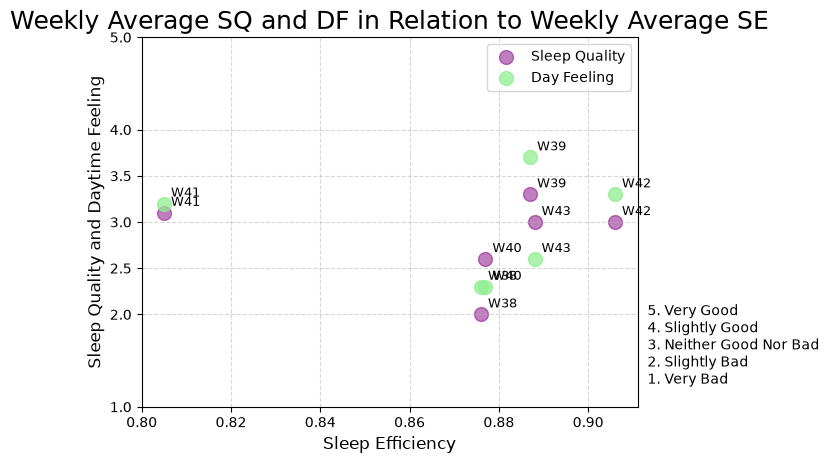

In [ ]:
#Figure 3.1
SE=data["sleep_efficiency"]                                     #x-axis
DF=data["day_feeling"]                                          #Also x-axis
SQ=data["sleep_quality"]                                        #y-axis

plt.scatter(SE,SQ,                                              #x and y axis in scatterplot for Sleep Quality (SQ) (Bro Code, 2025; Karina Adcock, 2023)
            color="purple",                                     #Color (Hunter et al., 2026a; Phillips, 2022).
            alpha=0.5,                                          #Transparancy
            s=100,                                              #Size of dots
            label="Sleep Quality"                               #For plt.legend() (Hunter et al., 2026c)
        )

plt.scatter(SE,DF,                                              #x and y axis in scatterplot for Daytime Feeling (DF) (Bro Code, 2025; Karina Adcock, 2023)
            color="lightgreen",                                 #Color (Hunter et al., 2026a; Phillips, 2022).
            alpha=0.75,                                         #Transparancy
            s=100,                                              #Size of dots
            label="Day Feeling"                                 #For plt.legend() (Hunter er al., 2026c)
        )

plt.title("Weekly Average SQ and DF in Relation to Weekly Average SE", fontsize=18)                 #Title
plt.xlabel("Sleep Efficiency", fontsize=12)                                                         #x-axis label
plt.ylabel("Sleep Quality and Daytime Feeling", fontsize=12)                                        #y-axis label
plt.ylim(1, 5)                                                                                      #To get the graph to show 1-5 instead of 2-3.75 where my values lie (Matplotlib.pyplot.yticks(), 2025)
plt.yticks([1, 2, 2.5, 3, 3.5, 4, 5])                                                               #To not get .5 or .75 values, but then added 2.5 and 3.5 since those are two common values for my graph to be within
plt.grid(True, linestyle="--", alpha=0.5)                                                           #To get a grid so it is easier to see the where the values are (Grids in Matplotlib, 2026)

for i, week in enumerate(data["week"]):                                                             #So that the name of the week appears next to the dots belonging to sleep quality (SQ) (Kimberly Fessel, 2021)
    plt.annotate(
        week,                                                                                       #Data from dataset for the program to use
        (SE.iloc[i], SQ.iloc[i]),           
        #"SE.iloc" is for the x-axis so essentially "x.iloc". Same for "SQ.iloc" but for the y axis so essentially "y.iloc". i is for coordinates for each datapoint
        fontsize=9,
        xytext=(5, 5),
        textcoords="offset points"
    )

for i, week in enumerate(data["week"]):                                                             #So that the name of the week appears next to the dots belonging to daytime feeling (DF). It is otherwise the exact same as above (Kimberly Fessel, 2021)
    plt.annotate(
        week,
        (SE.iloc[i], DF.iloc[i]),
        fontsize=9,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.text(                                                                                           #Adds text (Hunter et al., 2026e; Kimberly Fessel, 2021)
    1.02, 0.05,                                                                                     #Places text on grid so it shows up on x- and y-axis
    "5. Very Good  \n4. Slightly Good \n3. Neither Good Nor Bad \n2. Slightly Bad \n1. Very Bad",   #The added text. \n is for a new line.
    transform=plt.gca().transAxes,                                                                  #So that it has a grid to place the text
    fontsize=10,                                                                                    #Fontsize
    verticalalignment="bottom",                                                                     #Places text at bottom
)

plt.legend()                                                                                        #Displays names for datatypes (Hunter et al., 2026c)
plt.show()                                                                                          #Displays graph

#### Results
Some of the results in this figure(3.1) are unexpected as there is little to no correlation with sleep efficiency for both sleep quality(H6A) and day time feeling(H6B), with week 41 being a clear outlier. Despite poor sleep efficiency the SQ and DF ratings are rather good for this week which may be due to unknown confounders and should thus be further analyzed. Although sleep efficiency is rather good on average (generally above 86%) the average SQ and DF ratings are lower than one might expect, but due to chronic condition interference this is not a complete surprise. It does however suggest that although sleep hygiene is improving, particularly the time points between bedtime and sleep onset time in the evening habits line graph, there may be other underlying conditions that have not been measured such as deep sleep duration or other plausible confounders. H6 should therefore be rejected. However, as expected sleep quality and daytime feeling show similar average weekly ratings and H5 can be confirmed. A good sleep quality correlates with a good daytime feeling where the daytime feeling is better rated than the sleep quality (with some exceptions such as week 40 and 43). 

Although not hypothesized on, the figure also shows that sleep quality has no gradual improvement and starts off relatively high(normal SE for a healthy adult is ≥85%), which suggests that any improvement to my sleep might be more likely to come from introducing habits that improve sleep hygiene such as less time spent awake in bed, or unmeasured habits such as a clear wind-down period prior to getting into bed or physical activity during the day.

#### Why a Scatter Plot?
A scatter plot was chosen as it allows me to examine whether there is a correlation between good sleep efficiency and sleep quality aswell as daytime feeling (Bro Code, 2025; Karina Adcock, 2023). Additionally it allows me to examine the relationship between daytime feeling and sleep quality, although this will be further examined in the next figure. 

#### Color Choices
As with previous figures the colors have been chosen to maintain color consistency. Sleep Quality has been made purple to align with the darker blue hue theme associated with sleep whereas Daytime Feeling has been made green(lightgreen) to align with the bright and awake yellow theme for morning habits and by extension daytime feeling. Green was chosen as there are limited yellow hues that are appropriate for figures while remaining clear and visible, aswell as it contrasting well with purple for the color impaired. Yellow-purple contrasts far less as it may trigger blue-yellow colorblindness despite the warmer tone in the purple, and a warm green with a hint of yellow is thus a far more natural choice given the overarching color themes and accessibility needs (Hunter et al., 2026a; Phillips, 2022).

#### Additional Visual Choices
The dots have been given a visually appropriate size and have been made appropriately transparent. Due to the green being a far lighter color it has been made less transparent to retain visibility and not make the purple dots feel overpowering. Some data entries have overlapping text and are thus near impossible to read (e.g. W38 and W40). However, this has been kept in the figure as I do not know how to move the text for only a few data entries.

The title uses abbreviations for sleep quality(SQ), daytime feeling(DF), and sleep efficiency(SE) to shorten the length in order to keep the figure visually appealing, maintain an appropriate title fontsize, and reduce deadspace.

A grid has been added for accessibility while being semi transparent as to not make visual clutter (Grids in Matplotlib, 2026). Due to the original scale for SQ and DF ranging from 1(very bad) to 5(very good) the y axis has been altered to include all five values despite no datapoints being above or below 2-4. Due to the datapoints being consentrated within these values I decided to add 2.5 and 3.5 to the y-axis to make the plot more accessible. 1.5 and 4.5 have not been added as to reduce unecessary visual clutter (Matplotlib.pyplot.yticks(), 2025). Since the values 1-5 mean nothing on their own I have added a plt.text() to this figure that places text on the right hand side explaining what these values mean (Hunter et al., 2026e; Kimberly Fessel, 2021). It starts with "5. Very Good" and ends with "1. Very Bad" to follow the order presented in the Y-axis. This additional text has been coded so that each value has its own line. This makes the figure more visually appealing as well as space saving.


### 3.2 Line Graph: Weekly Trends in Sleep Quality and Daytime Feeling

In addition to the scatter plot(figure 3.1) I am interested in the development of my sleep health, particulatly my sleep quality(SQ) and daytime feeling(DF) since my sleep efficiency has been stable within the healthy boundaries(≥85%) throughout this project. Although expectations are low, the goal is for both SQ and DF to gradually improve over time. I therefore hypothesize that:

H7:     Average weekly Sleep Quality has a positive correlation with average weekly Daytime Feeling.

H8:    Average weekly Sleep Quality (H8A) and average weekly Daytime Feeling(H8B) increases over time.

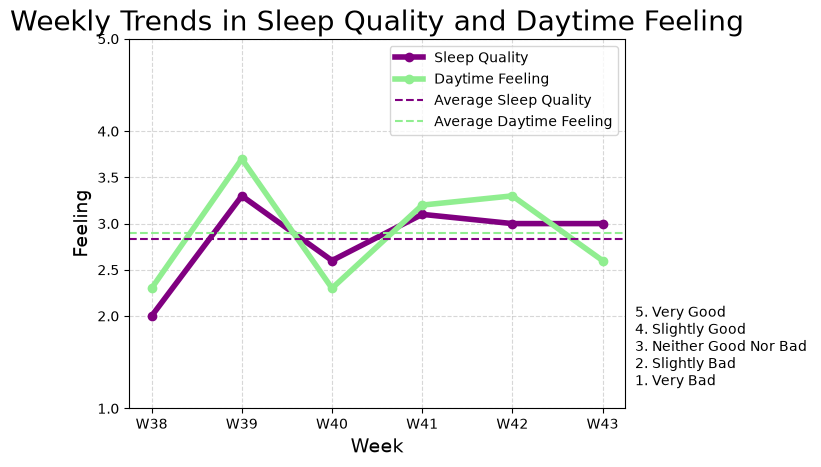

In [ ]:
#Figure 3.2
week=data["week"]                                         #x-axis
SQ=data["sleep_quality"]                                  #y-axis
DF=data["day_feeling"]                                    #Also y-axis

avg_SQ = sum(SQ) / len(SQ)                                #To get the average sleep quality, useful for when dataset has grown larger
avg_DF = sum(DF) / len(DF)                                #To get the average daytime feeling, useful for when dataset has grown larger


plt.plot(                                                 #To get the plotted line for sleep quality(SQ) (Visually Explained, 2025)
 week,                                                    #x-axis
 SQ,                                                      #y-axis
 marker="o",                                              #To make each datapoint more visible
 label= "Sleep Quality",                                  #For plt.legend() to have the name of the line for sleep quality in the plot (Hunter et al., 2026c)
 color="purple",                                          #Color (Hunter et al., 2026a; Phillips, 2022)
 linewidth=4                                              #Width of the line
)

plt.plot(                                                 #Same as above but for daytime feeling (Visually Explained, 2025)
     week,
     DF,
     marker="o",
     label="Daytime Feeling",                             #(Hunter et al., 2026c)
     color="lightgreen",                                  #(Hunter et al., 2026a; Phillips, 2022)
     linewidth=4
)


plt.title("Weekly Trends in Sleep Quality and Daytime Feeling", fontsize=20)                        #Title
plt.xlabel("Week", fontsize=14)                                                                     #x-axis label
plt.ylabel("Feeling", fontsize=14)                                                                  #y-axis label. Generalised to fit both SQ and DF
plt.axhline(avg_SQ, linestyle="--", color="purple", label="Average Sleep Quality")                  #The average for Sleep Quality with label for plt.legend() and appropriate styling (Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022).
plt.axhline(avg_DF, linestyle="--", color="lightgreen", label="Average Daytime Feeling")            #The average for Daytime Feeling with label for plt.legend() and appropriate styling (Hunter et al., 2026a; Hunter et al., 2026c; Phillips, 2022).
plt.ylim(1, 5)                                                                                      #To get the graph to show 1-5 instead of 2-3.75 where my values lie (Matplotlib.pyplot.yticks(), 2025)
plt.yticks([1, 2, 2.5, 3, 3.5, 4, 5])                                                               #To not get .5 or .75 values, but then added 2.5 and 3.5 since those are two common values for my graph to be within
plt.grid(True, linestyle="--", alpha=0.5)                                                           #To get a grid so it is easier to see the where the values are (Grids in Matplotlib, 2026)

plt.text(                                                                                           #Adds text (Hunter et al., 2026e; Kimberly Fessel, 2021)
    1.02, 0.05,                                                                                     #Places text on grid so it shows up on x- and y-axis
    "5. Very Good  \n4. Slightly Good \n3. Neither Good Nor Bad \n2. Slightly Bad \n1. Very Bad",   #The added text. \n is for a new line.
    transform=plt.gca().transAxes,                                                                  #So that it has a grid to place the text
    fontsize=10,                                                                                    #Fontsize
    verticalalignment="bottom",                                                                     #Places text at bottom
)


plt.legend()                                                                                        #Displays names for dataline (Hunter et al., 2026c)
plt.show()                                                                                          #Displays graph

#### Results
The line graph(figure 3.2) shows a positive correlation between average weekly sleep quality and average weekly daytime feeling. H7 — as was also the case in the scatterplot(figure 3.1) and H5 — can thus be confirmed. H8 however may be rejected. As of now there is no clear increase over time, although this may change as more data is entered. The current graph shows a wide range of reported values (between 2 and 3.7), but recent data entries suggest that this gap is slowly shrinking to average between 2.5 and 3.5 and thus a possible increase over time. Albeit a slow increase that may plateu and thus supporting that H8 should be rejected. The lack of visible improvement in SQ and DF in the span of over a month with active attempts to improve sleep may suggest that although sleep hygiene improves — which makes sleep health more reliable and thus reducing the wide span in reported SQ and DF — there may be underlying undiagnosed health concerns (e.g. disturbed deep sleep) which impact the reported SQ and DF. This is particularly likely as sleep efficiency in figure 3.1 is well within normal boundaries.

#### Why a Line Graph?
A line graph was chosen in order to map the development of SQ and DF. It gives a clear view of the relationship between the two and whether progress is being made (Visually Explained, 2025).

#### Color Choices
The colors are the same as in figure 3.1 as this figure is using the same variables. Changing the colors would then disturb the color consistency and potentially make the figures confusing (Hunter et al., 2026a; Phillips, 2022).

#### Additional Visual Choices
The grid, y-axis, and text choices remain the same as in figure 3.1 for the same reasons (Grids in Matplotlib, 2026; Hunter et al., 2026d; Matplotlib.pyplot.yticks(), 2025). Aswell as each data point being marked with a dot, and the plt.legend() (Hunter et al., 2026c; Kimberly Fessel, 2021) like in figures 2.1 and 2.2 for accessibility reasons.

## Reference List

Bro Code (2025, October 5) _Matplotlib scatter plots in 6 minutes! ✨_ [Video]. YouTube. https://youtu.be/HHrG5W530fk?si=IiU965FuQ5woq7kd

_Grids in Matplotlib_ (2026). geeksforgeeks. https://www.geeksforgeeks.org/python/grids-in-matplotlib/

Hunter, J., Dale, D., Firing, E., Droettboom, M., & the Matplotlib development team. (2026). _List of named colors_. matplotlib. https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html

Hunter, J., Dale, D., Firing, E., Droettboom, M., & the Matplotlib development team. (2026). _Major and minor ticks_. matplotlib.
https://venus.matplotlib.org/stable/gallery/ticks/major_minor_demo.html

Hunter, J., Dale, D., Firing, E., Droettboom, M., & the Matplotlib development team. (2026). _matplotlib.pyplot.legend_. matplotlib. https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html

Hunter, J., Dale, D., Firing, E., Droettboom, M., & the Matplotlib development team. (2026). _matplotlib.ticker_. matplotlib.
https://matplotlib.org/stable/api/ticker_api

Hunter, J., Dale, D., Firing, E., Droettboom, M., & the Matplotlib development team. (2026). _Placing text boxes_. matplotlib.
https://matplotlib.org/stable/gallery/text_labels_and_annotations/placing_text_boxes.html

Karina Adcock (2023, September 20) _How to make scatter plot with trendline and stats in python_ [Video]. YouTube. https://youtu.be/lapKRrSdn_U?si=xFho8jFS_p8E2aA1

Kimberly Fessel (2021, February 8) _Add TEXT to MATPLOTLIB figures || Python matplotlib text with plt.text() || Matplotlib Tips_ [Video]. YouTube. https://youtu.be/NBYzSaTbodM?si=iyU5VYPyu24Pet_4

_Matplotlib.pyplot.yticks() in Python_ (2025). geeksforgeeks. https://www.geeksforgeeks.org/python/matplotlib-pyplot-yticks-in-python/

_pandas.Timedelta_ (n.d.). pandas. Retrieved October 21, 2026 from https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Timedelta.html

Phillips, A. (2022, June 29). _Colorblind Safe Color Schemes_ NCEAS Science Communication Resource Corner. https://www.nceas.ucsb.edu/sites/default/files/2022-06/Colorblind%20Safe%20Color%20Schemes.pdf

Simply Coding (2020, April 2) _Python Pie Chart_ [Video]. YouTube. https://youtu.be/8GdvRNblTqg?si=bjGwWTz0h6Ph5fmg

_Time deltas_ (n.d.). pandas. Retrieved October 21, 2026 from https://pandas.pydata.org/docs/user_guide/timedeltas.html

Visually Explained (2025, January 20) _Matplotlib (Python Library) - Visually Explained_ [Video]. YouTube. https://youtu.be/gamozygB2xE?si=RlCxFo0N7PCMSZPz